In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.sparse import issparse
from scipy.stats import mannwhitneyu
import scanpy as sc
import tqdm
import functools
import glob
import gzip as gz
import itertools
import math
import os
import sys
from importlib import reload

sys.path.append('/Genomics/pritykinlab/dillon/perturbseq/scripts/utils')
import misc

In [2]:
plt.rcParams["axes.titlesize"] = 25
plt.rcParams["axes.labelsize"] = 25
plt.rcParams["xtick.labelsize"] = 20
plt.rcParams["ytick.labelsize"] = 20
plt.rcParams["lines.markersize"] = 5
plt.rcParams['axes.grid'] = False
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True
plt.rcParams['xtick.major.size'] = 5
plt.rcParams['xtick.minor.size'] = 3
plt.rcParams['ytick.major.size'] = 5
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams['axes.labelcolor'] = 'black'
plt.rcParams['axes.edgecolor'] = 'black'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.title_fontsize'] = 15
plt.rcParams['legend.edgecolor'] = 'dimgray'
plt.rcParams['figure.figsize'] = (7,7)


# Initial Processing and Filtering Out cells

In [3]:
adata = sc.read_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/02_LP.h5ad")

In [5]:
adata.shape

(47212, 22603)

In [4]:
reload(misc)
adata = misc.score_cell_cycle_genes(adata)

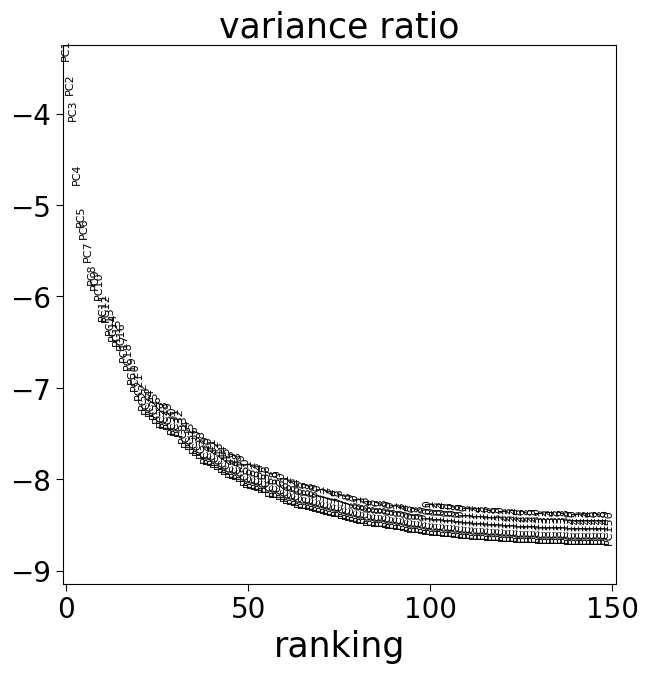

In [5]:
adata.raw = adata
adata.X = adata.X.toarray()
sc.pp.normalize_total(adata, exclude_highly_expressed=True)
adata.layers['norm'] = adata.X.copy()
sc.pp.log1p(adata)
adata.layers['norm_log'] = adata.X.copy()
sc.pp.scale(adata, max_value=10)
adata.layers['norm_log_zscore'] = adata.X.copy()
sc.tl.pca(adata, svd_solver='arpack', n_comps=150)
sc.pl.pca_variance_ratio(adata, n_pcs=150, log=True)

In [6]:
sc.pp.neighbors(adata, n_neighbors=20, n_pcs=75)
sc.tl.umap(adata)

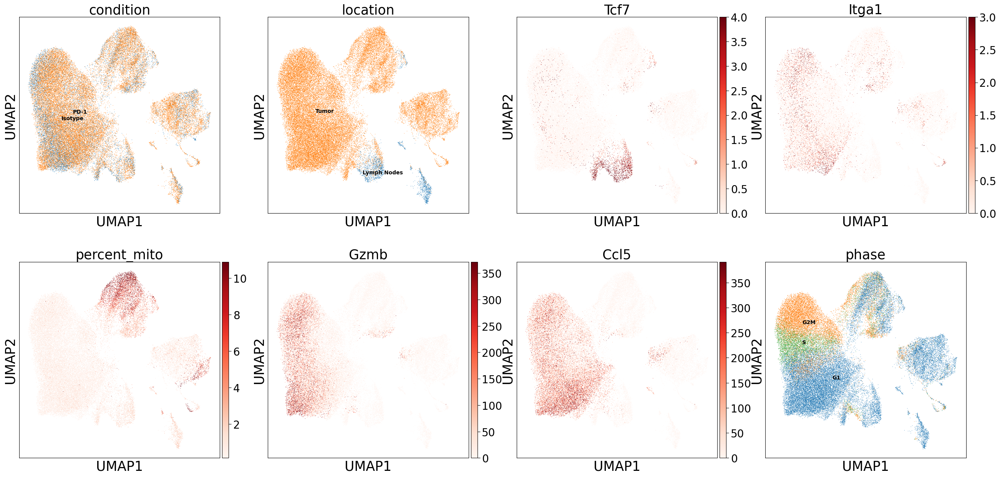

In [7]:
sc.pl.umap(adata, color=['condition', 'location', 'Tcf7', 'Itga1', 'percent_mito', 'Gzmb', 'Ccl5', 'phase'],
           legend_loc='on data', cmap='Reds', vmin="p2", vmax="p98")

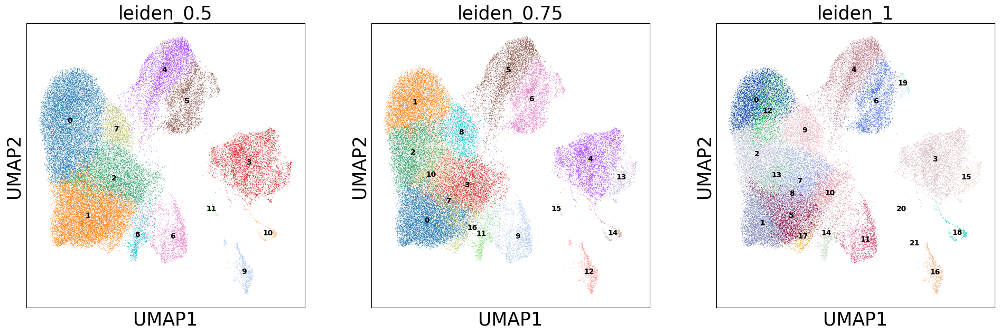

############################ leiden_0.5 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10
Processing cluster 11


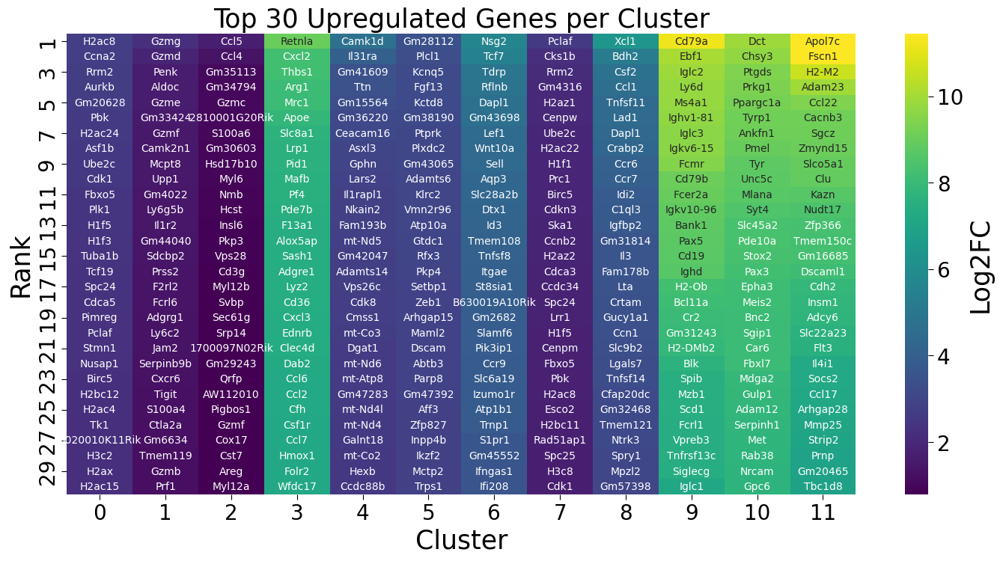

############################ leiden_0.75 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10
Processing cluster 11
Processing cluster 12
Processing cluster 13
Processing cluster 14
Processing cluster 15
Processing cluster 16


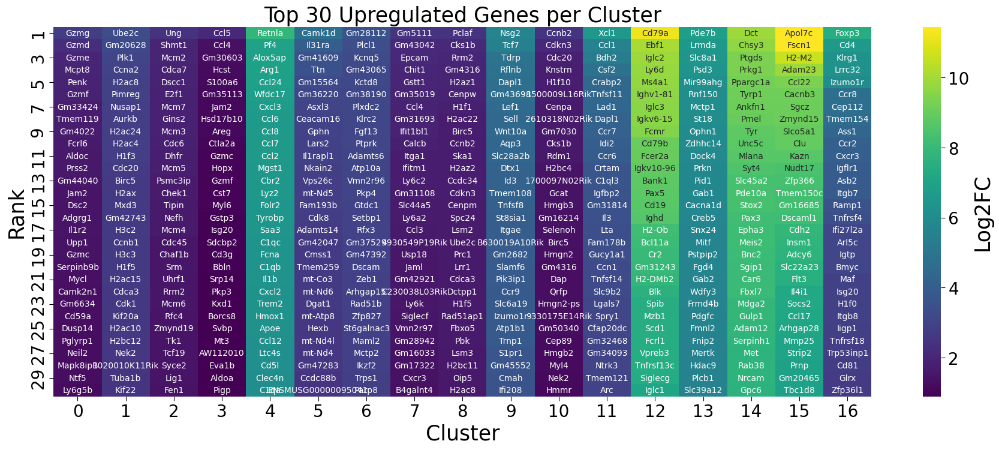

############################ leiden_1 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10
Processing cluster 11
Processing cluster 12
Processing cluster 13
Processing cluster 14
Processing cluster 15
Processing cluster 16
Processing cluster 17
Processing cluster 18
Processing cluster 19
Processing cluster 20
Processing cluster 21


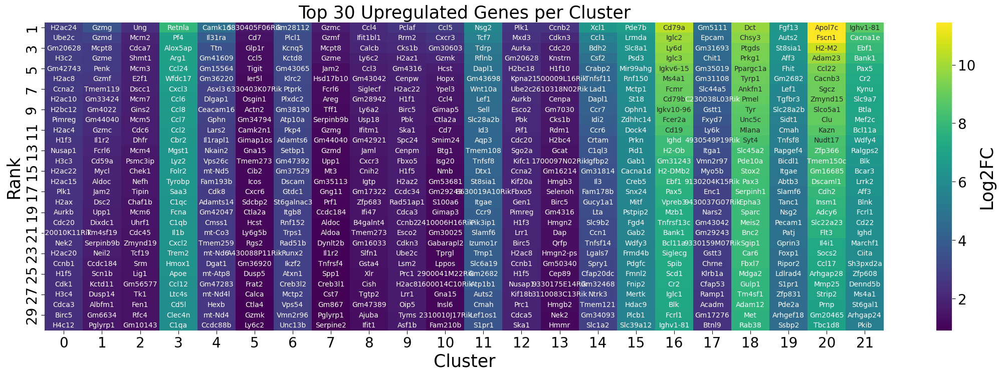

In [8]:
import DE_testing
reload(DE_testing)
all_de_results = DE_testing.apply_multi_resolution_clustering_then_heatmaps(adata, [0.5, 0.75, 1])

In [9]:
adata.write_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/03_filter_cells_adata.h5ad")

# Read Adata

In [60]:
adata = sc.read_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/03_filter_cells_adata.h5ad")

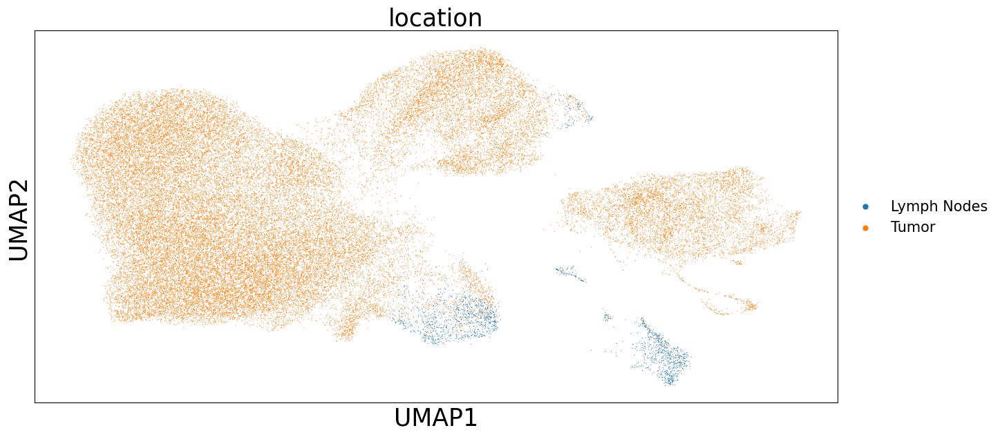

In [61]:
sc.pl.umap(adata, color='location')

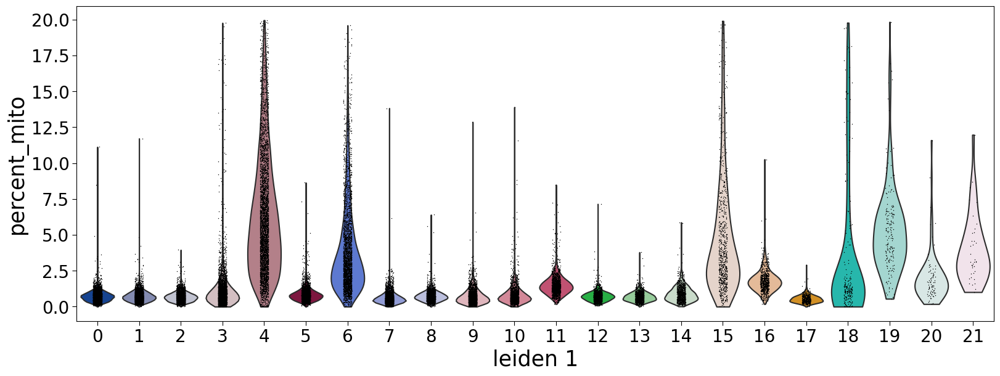

In [65]:
sc.pl.violin(adata, keys='percent_mito', groupby='leiden_1', layer='norm_log', use_raw=False)

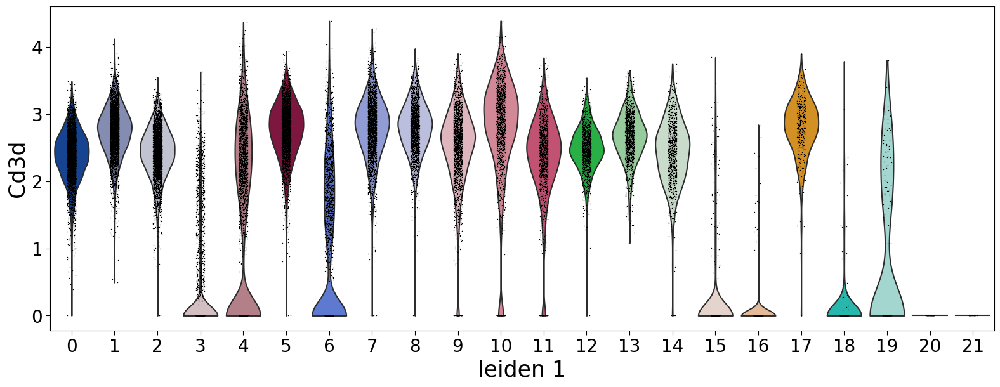

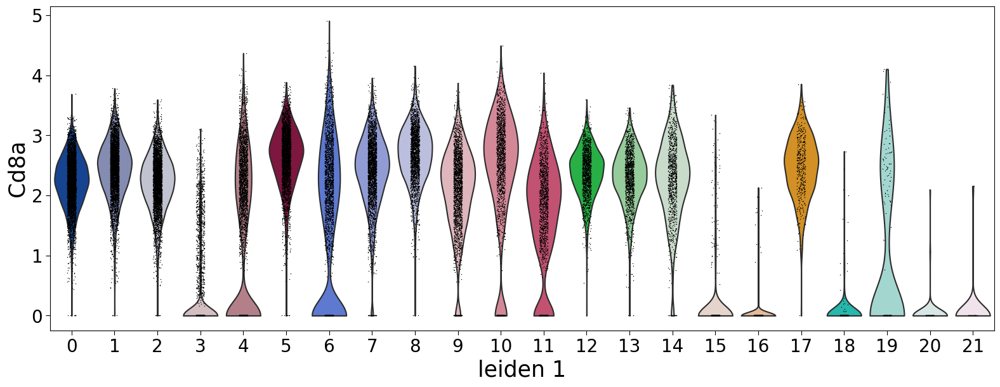

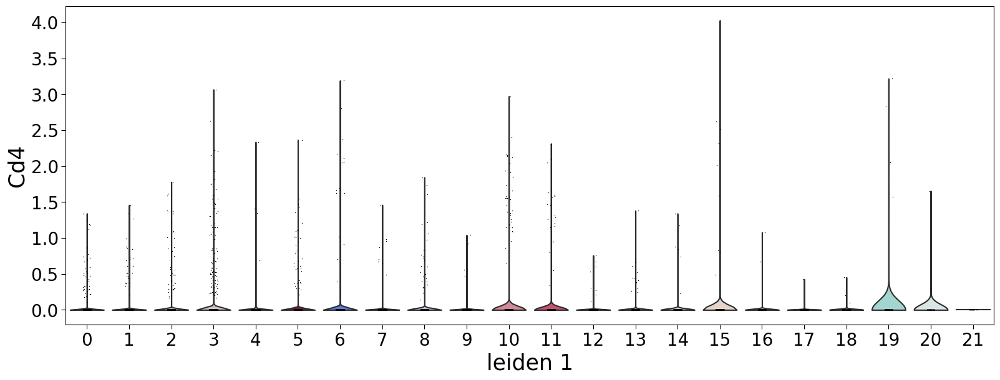

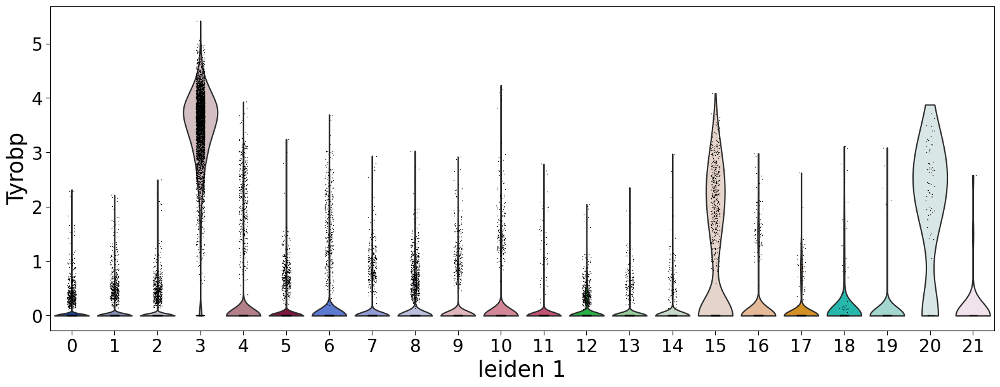

In [62]:
plt.rcParams['figure.figsize'] = (15,7)
for marker in ['Cd3d', 'Cd8a', 'Cd4', 'Tyrobp']:
    sc.pl.violin(adata, keys=[marker], groupby='leiden_1', layer='norm_log', use_raw=False)

In [63]:
# 3, 15, 16, 18, 20, 21

In [66]:
cells_to_keep = adata[~adata.obs['leiden_1'].isin(['4', '6', '19', '3', '15', '20', '18', '21', '16'])].obs_names

# Final Processing with Removed Cells

In [76]:
adata = sc.read_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/02_LP.h5ad")

adata = adata[adata.obs_names.isin(cells_to_keep)].copy()

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:843: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


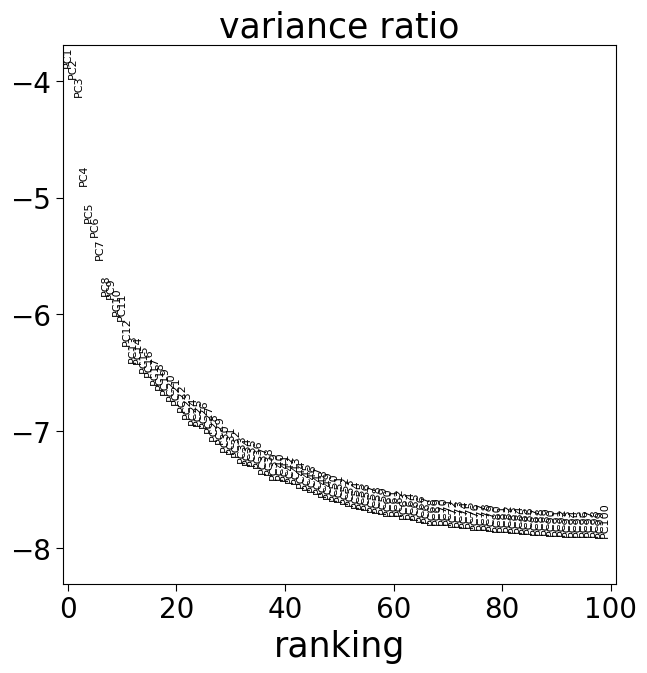

In [77]:
adata.raw = adata
adata.X = adata.X.toarray()
sc.pp.normalize_total(adata, exclude_highly_expressed=True)
adata.layers['norm'] = adata.X.copy()
sc.pp.log1p(adata)
adata.layers['norm_log'] = adata.X.copy()
sc.pp.highly_variable_genes(adata, n_top_genes=8000, flavor='seurat')
adata = adata[:, adata.var.highly_variable]
sc.pp.scale(adata, max_value=10)
adata.layers['norm_log_zscore'] = adata.X.copy()
sc.tl.pca(adata, svd_solver='arpack', n_comps=100)
sc.pl.pca_variance_ratio(adata, n_pcs=100, log=True)

In [78]:
adata = misc.my_score_cell_cycle_genes(adata)

10


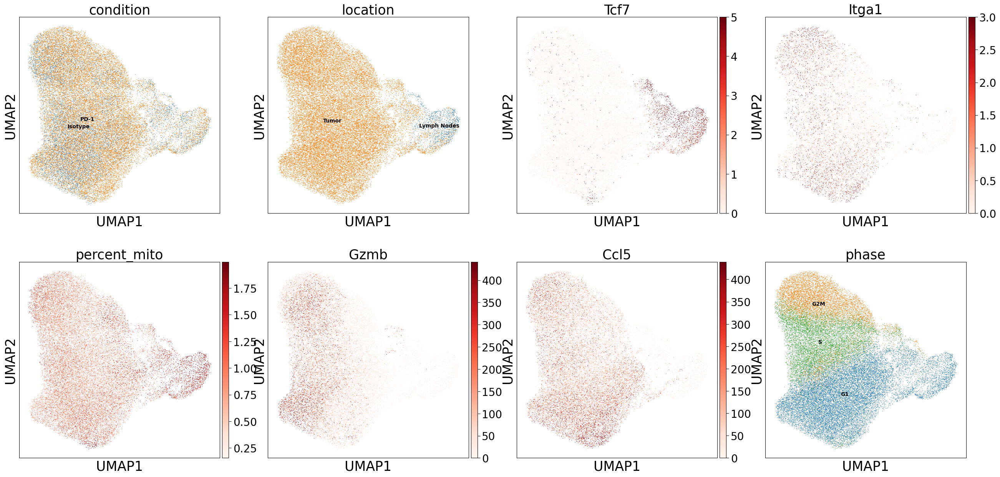

50


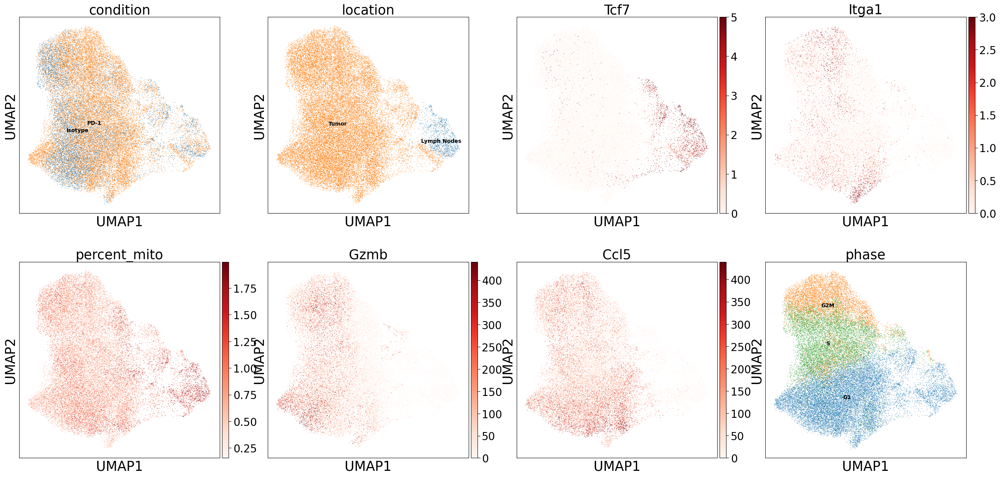

70


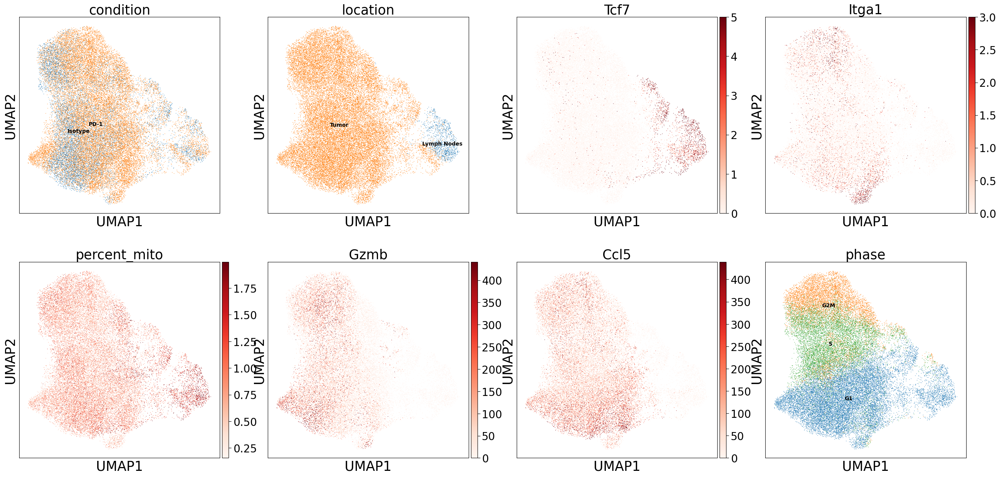

80


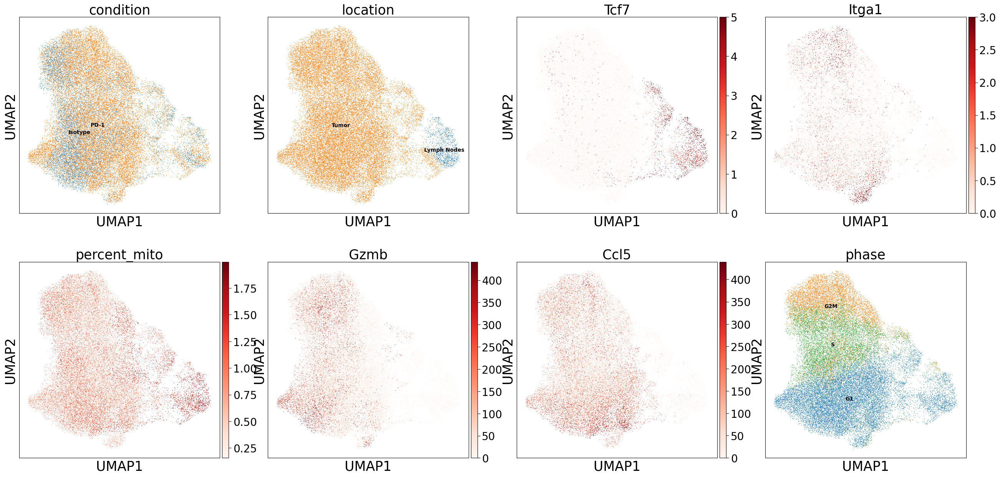

100


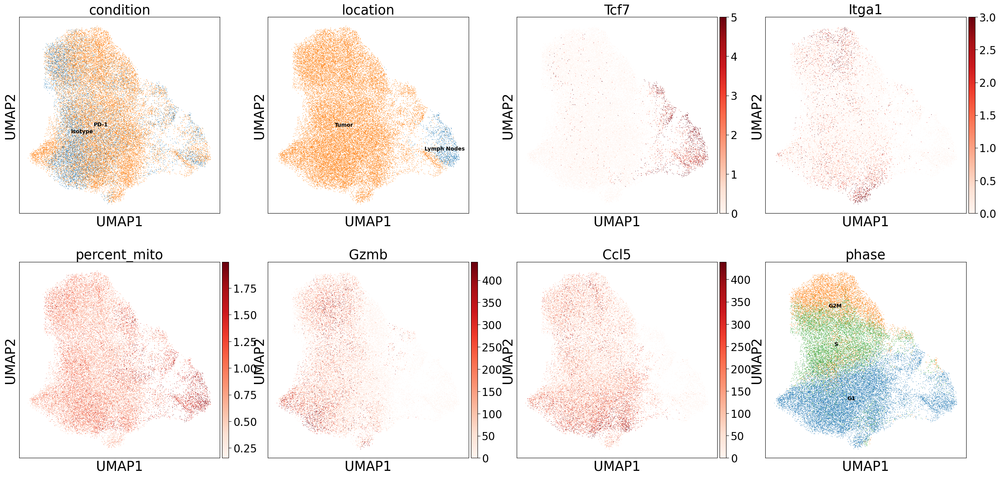

In [79]:
plt.rcParams["axes.titlesize"] = 25
plt.rcParams["axes.labelsize"] = 25
plt.rcParams["xtick.labelsize"] = 20
plt.rcParams["ytick.labelsize"] = 20
plt.rcParams["lines.markersize"] = 5
plt.rcParams['axes.grid'] = False
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True
plt.rcParams['xtick.major.size'] = 5
plt.rcParams['xtick.minor.size'] = 3
plt.rcParams['ytick.major.size'] = 5
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams['axes.labelcolor'] = 'black'
plt.rcParams['axes.edgecolor'] = 'black'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.title_fontsize'] = 15
plt.rcParams['legend.edgecolor'] = 'dimgray'
plt.rcParams['figure.figsize'] = (7,7)
for i in [10, 50, 70, 80, 100]:
    print(i)
    sc.pp.neighbors(adata, n_neighbors=20, n_pcs=i)
    sc.tl.umap(adata)

    sc.pl.umap(adata, color=['condition', 'location', 'Tcf7', 'Itga1', 'percent_mito', 'Gzmb', 'Ccl5', 'phase'],
               legend_loc='on data', cmap='Reds', vmin="p2", vmax="p98")

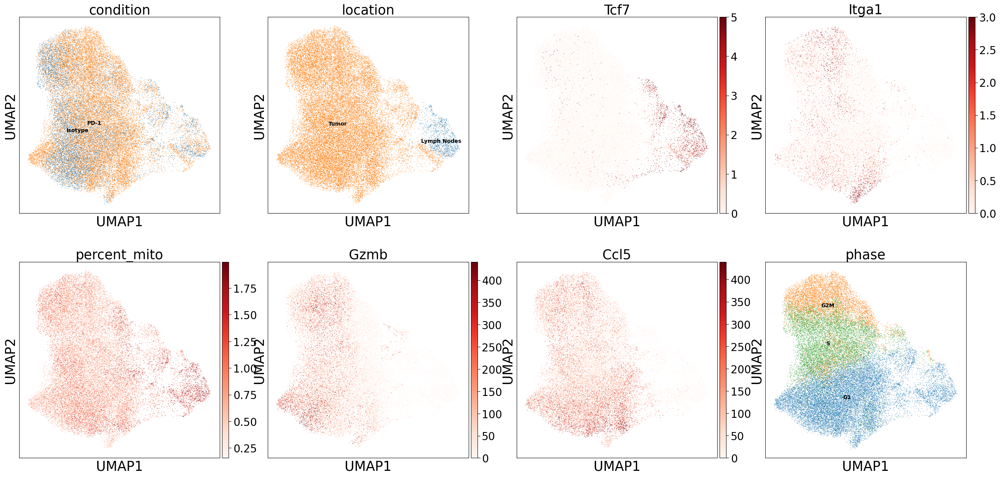

In [81]:
sc.pp.neighbors(adata, n_neighbors=20, n_pcs=50)
sc.tl.umap(adata)

sc.pl.umap(adata, color=['condition', 'location', 'Tcf7', 'Itga1', 'percent_mito', 'Gzmb', 'Ccl5', 'phase'],
           legend_loc='on data', cmap='Reds', vmin="p2", vmax="p98")

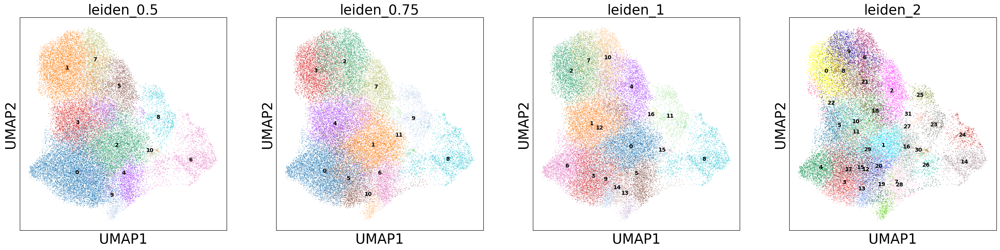

############################ leiden_0.5 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10


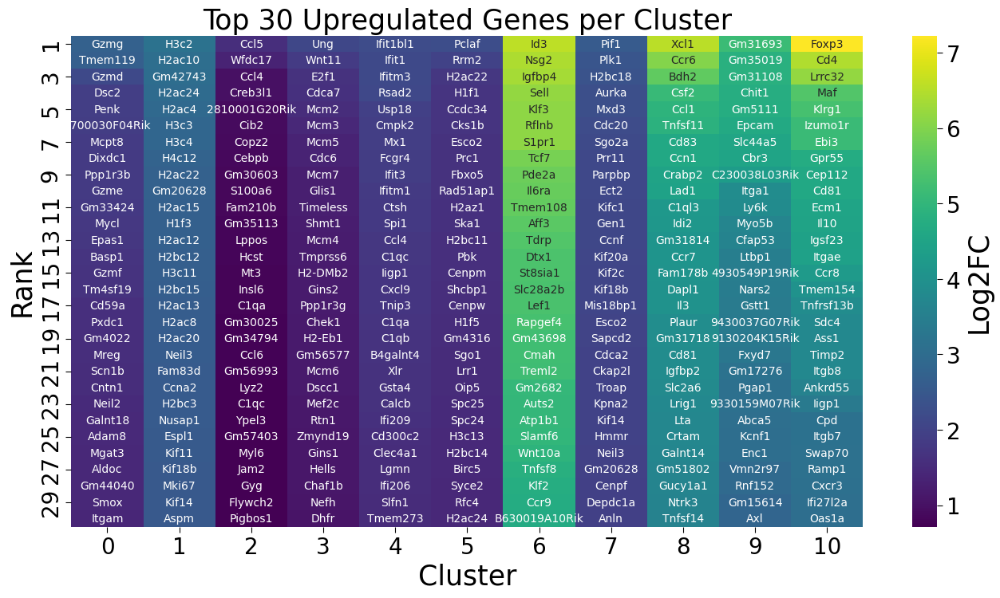

############################ leiden_0.75 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10
Processing cluster 11


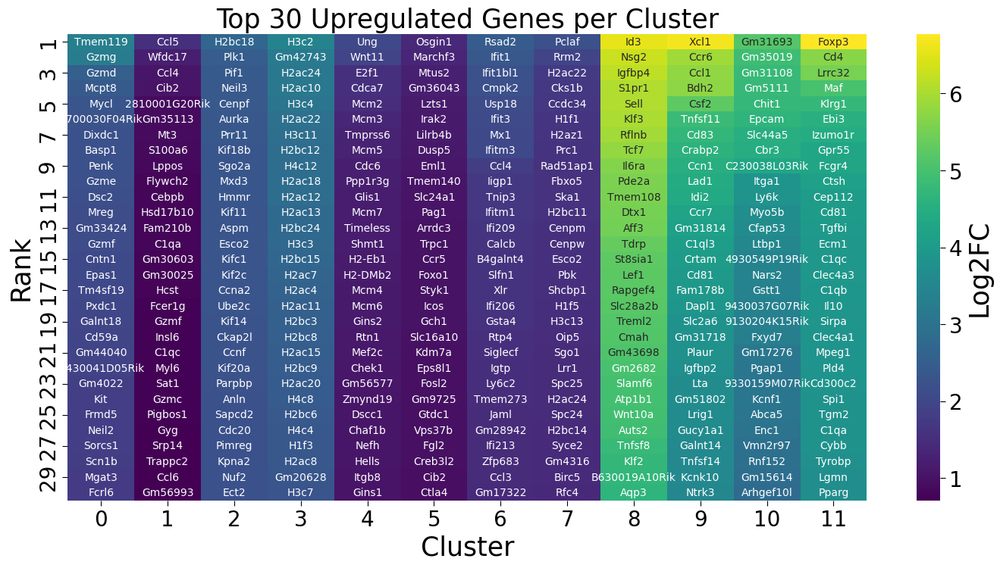

############################ leiden_1 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10
Processing cluster 11
Processing cluster 12
Processing cluster 13
Processing cluster 14
Processing cluster 15
Processing cluster 16


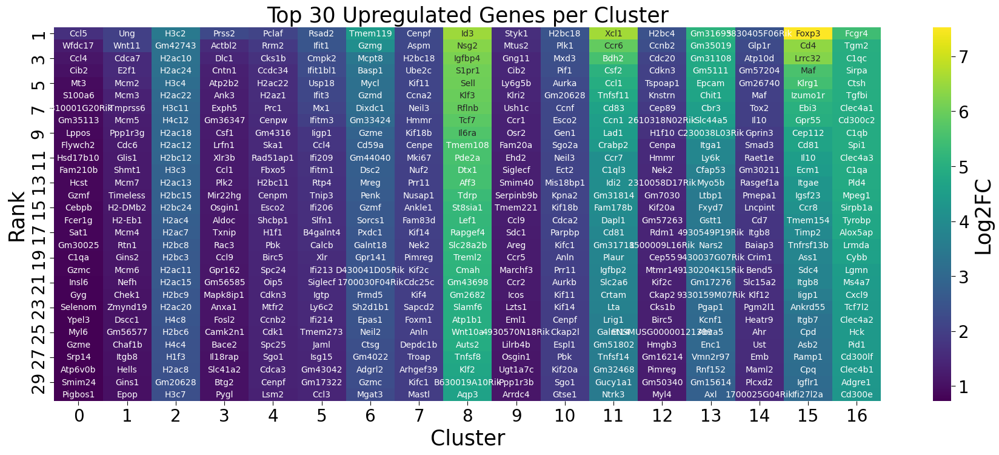

############################ leiden_2 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10
Processing cluster 11
Processing cluster 12
Processing cluster 13
Processing cluster 14
Processing cluster 15
Processing cluster 16
Processing cluster 17
Processing cluster 18
Processing cluster 19
Processing cluster 20
Processing cluster 21
Processing cluster 22
Processing cluster 23
Processing cluster 24
Processing cluster 25
Processing cluster 26
Processing cluster 27
Processing cluster 28
Processing cluster 29
Processing cluster 30
Processing cluster 31


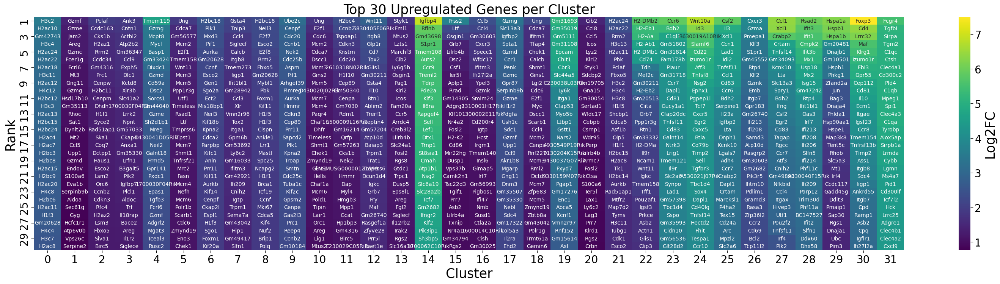

In [84]:
import DE_testing
reload(DE_testing)
all_de_results = DE_testing.apply_multi_resolution_clustering_then_heatmaps(adata, [0.5, 0.75, 1, 2])

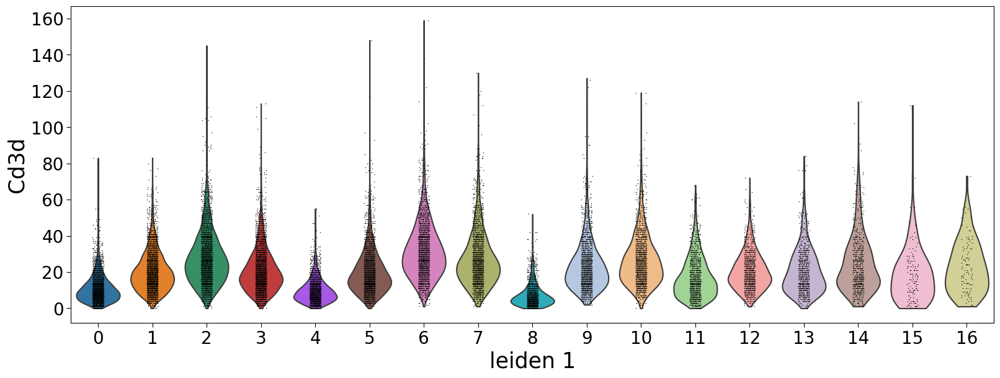

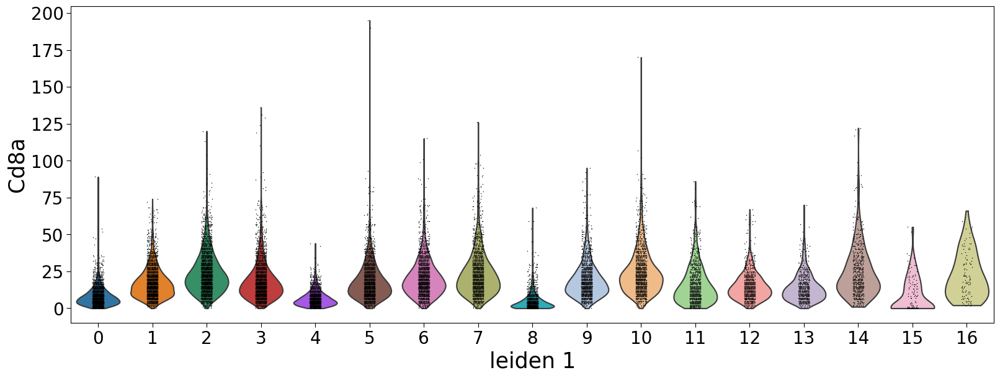

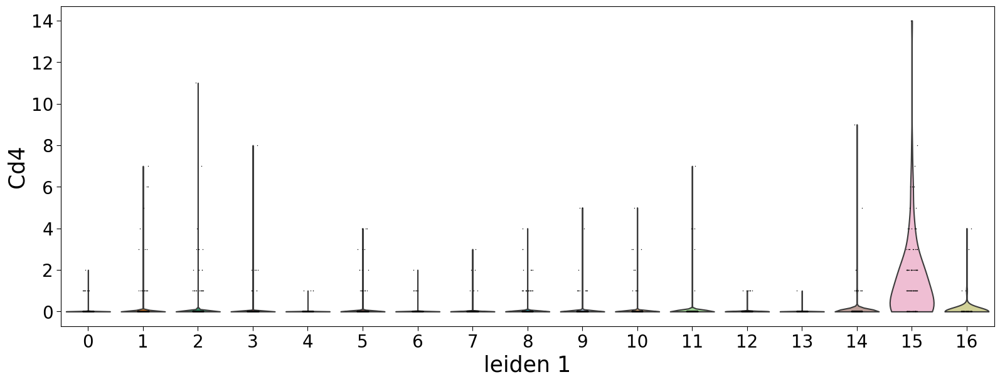

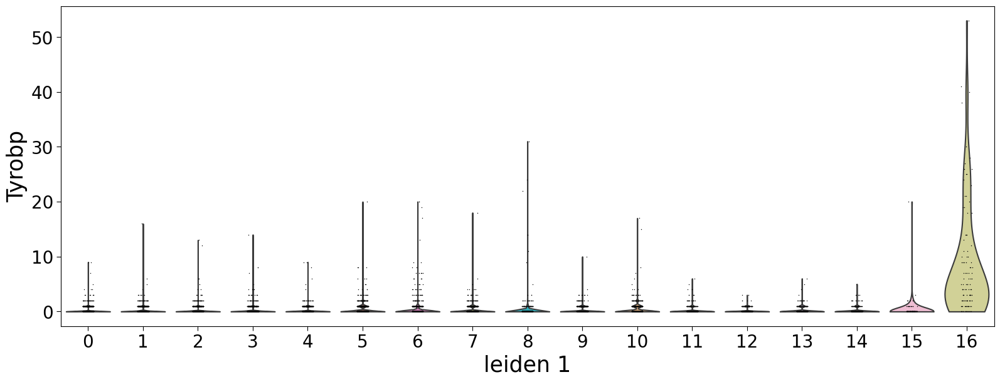

In [85]:
plt.rcParams['figure.figsize'] = (15,7)
for marker in ['Cd3d', 'Cd8a', 'Cd4', 'Tyrobp']:
    sc.pl.violin(adata, keys=[marker], groupby='leiden_1', use_raw=True)

In [86]:
# adata.write_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/04_filter_cells_adata.h5ad")

In [36]:
adata = sc.read_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/04_filter_cells_adata.h5ad")

In [ ]:
cells_to_keep = adata[~adata.obs['leiden_1'].isin(['15', '16'])].obs_names

# Round 2

In [95]:
adata = sc.read_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/02_LP.h5ad")

adata = adata[adata.obs_names.isin(cells_to_keep)].copy()

In [96]:
plt.rcParams['figure.figsize'] = (7,7)

/Genomics/pritykinlab/dillon/software/miniconda/envs/envs/scvi/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:843: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


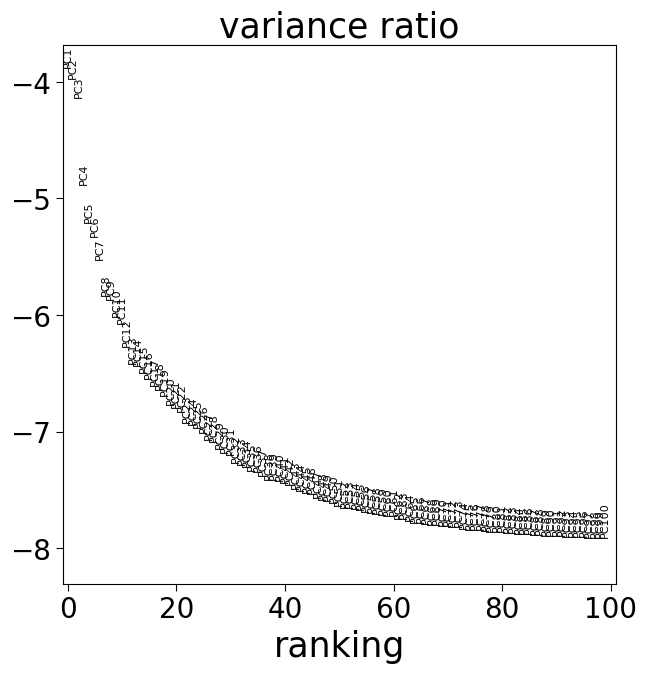

In [97]:
adata.raw = adata
adata.X = adata.X.toarray()
sc.pp.normalize_total(adata, exclude_highly_expressed=True)
adata.layers['norm'] = adata.X.copy()
sc.pp.log1p(adata)
adata.layers['norm_log'] = adata.X.copy()
sc.pp.highly_variable_genes(adata, n_top_genes=8000, flavor='seurat')
adata = adata[:, adata.var.highly_variable]
sc.pp.scale(adata, max_value=10)
adata.layers['norm_log_zscore'] = adata.X.copy()
sc.tl.pca(adata, svd_solver='arpack', n_comps=100)
sc.pl.pca_variance_ratio(adata, n_pcs=100, log=True)

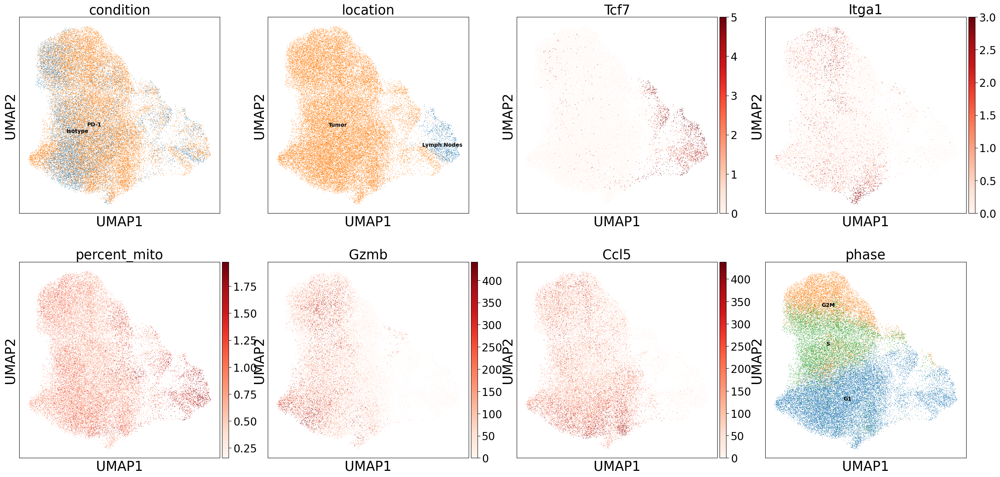

In [98]:
adata = misc.my_score_cell_cycle_genes(adata)
sc.pp.neighbors(adata, n_neighbors=20, n_pcs=50)
sc.tl.umap(adata)

sc.pl.umap(adata, color=['condition', 'location', 'Tcf7', 'Itga1', 'percent_mito', 'Gzmb', 'Ccl5', 'phase'],
           legend_loc='on data', cmap='Reds', vmin="p2", vmax="p98")

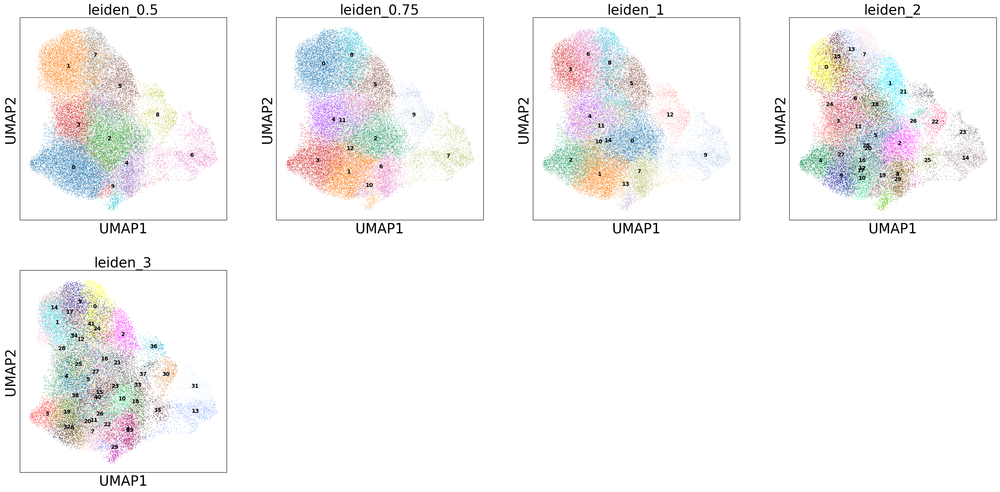

############################ leiden_0.5 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9


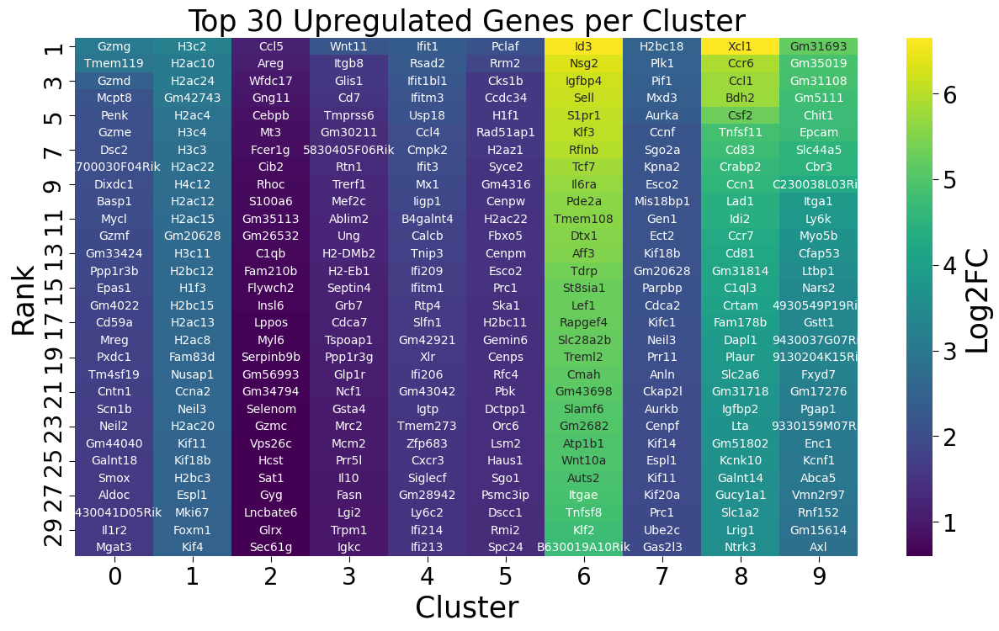

############################ leiden_0.75 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10
Processing cluster 11
Processing cluster 12


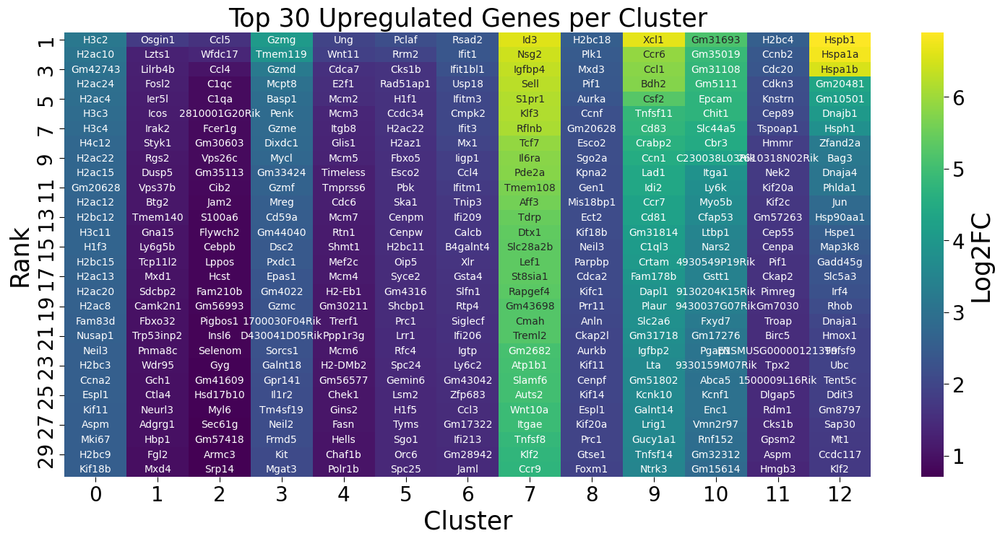

############################ leiden_1 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10
Processing cluster 11
Processing cluster 12
Processing cluster 13
Processing cluster 14


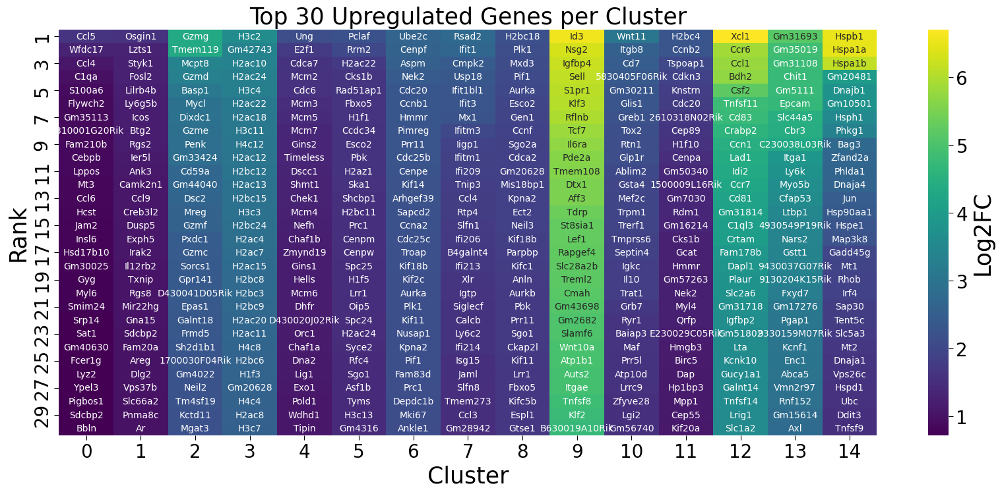

############################ leiden_2 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10
Processing cluster 11
Processing cluster 12
Processing cluster 13
Processing cluster 14
Processing cluster 15
Processing cluster 16
Processing cluster 17
Processing cluster 18
Processing cluster 19
Processing cluster 20
Processing cluster 21
Processing cluster 22
Processing cluster 23
Processing cluster 24
Processing cluster 25
Processing cluster 26
Processing cluster 27
Processing cluster 28
Processing cluster 29


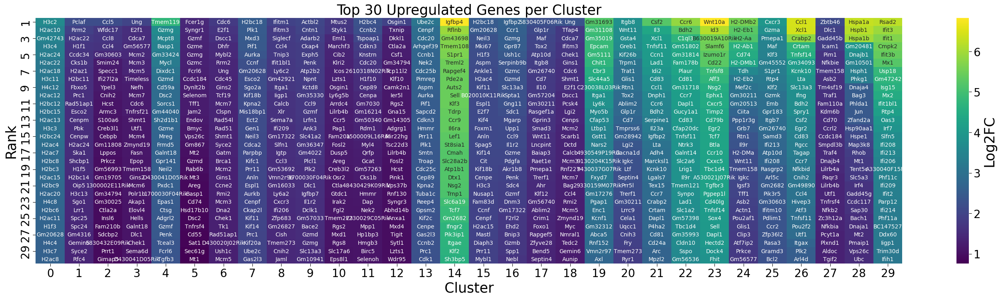

############################ leiden_3 ##################################
Processing cluster 0
Processing cluster 1
Processing cluster 2
Processing cluster 3
Processing cluster 4
Processing cluster 5
Processing cluster 6
Processing cluster 7
Processing cluster 8
Processing cluster 9
Processing cluster 10
Processing cluster 11
Processing cluster 12
Processing cluster 13
Processing cluster 14
Processing cluster 15
Processing cluster 16
Processing cluster 17
Processing cluster 18
Processing cluster 19
Processing cluster 20
Processing cluster 21
Processing cluster 22
Processing cluster 23
Processing cluster 24
Processing cluster 25
Processing cluster 26
Processing cluster 27
Processing cluster 28
Processing cluster 29
Processing cluster 30
Processing cluster 31
Processing cluster 32
Processing cluster 33
Processing cluster 34
Processing cluster 35
Processing cluster 36
Processing cluster 37
Processing cluster 38
Processing cluster 39
Processing cluster 40
Processing cluster 41


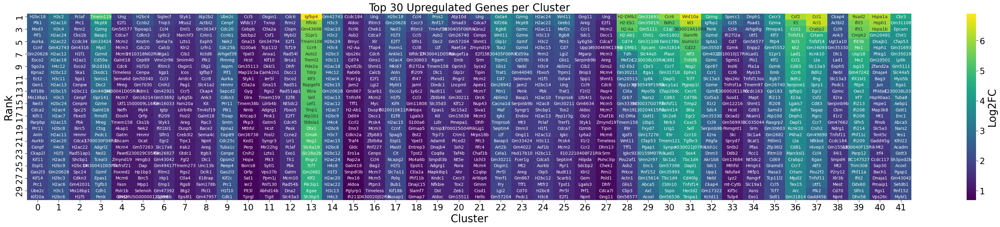

In [4]:
import DE_testing
reload(DE_testing)
all_de_results = DE_testing.apply_multi_resolution_clustering_then_heatmaps(adata, [0.5, 0.75, 1, 2, 3])

In [5]:
# adata.write_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/05_filter_cells_adata.h5ad")

In [33]:
adata = sc.read_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/05_filter_cells_adata.h5ad")

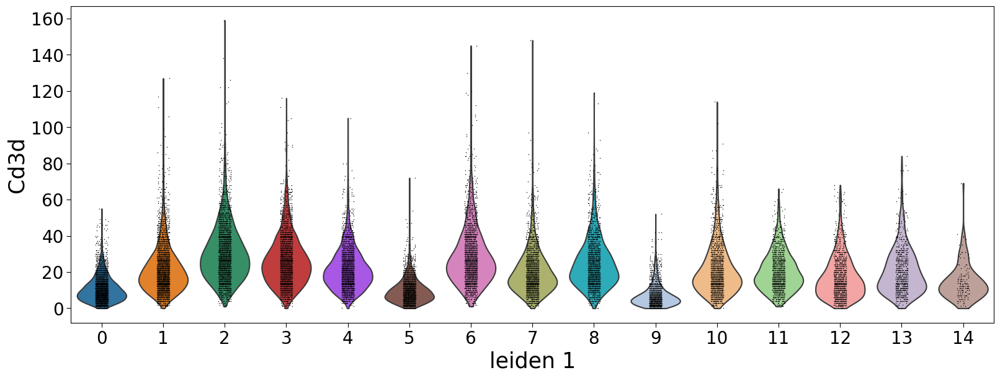

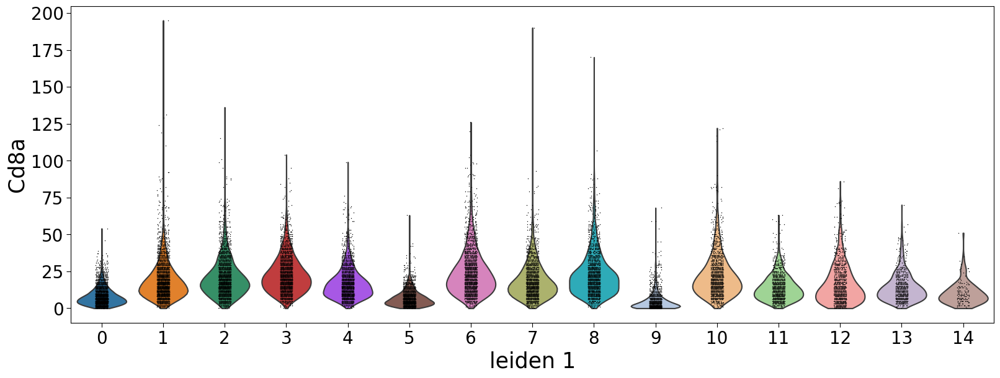

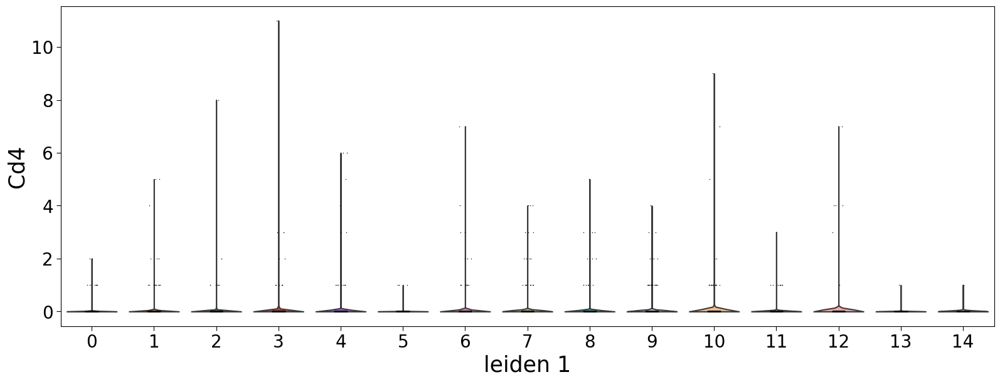

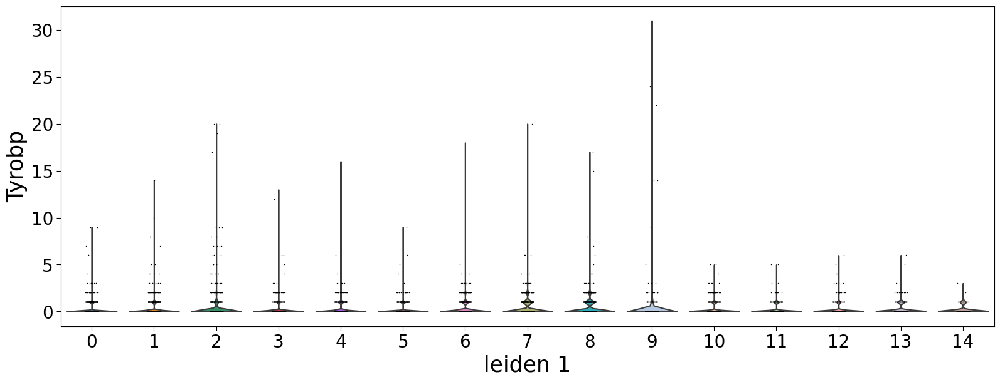

In [34]:
plt.rcParams['figure.figsize'] = (15,7)
for marker in ['Cd3d', 'Cd8a', 'Cd4', 'Tyrobp']:
    sc.pl.violin(adata, keys=[marker], groupby='leiden_1', use_raw=True)

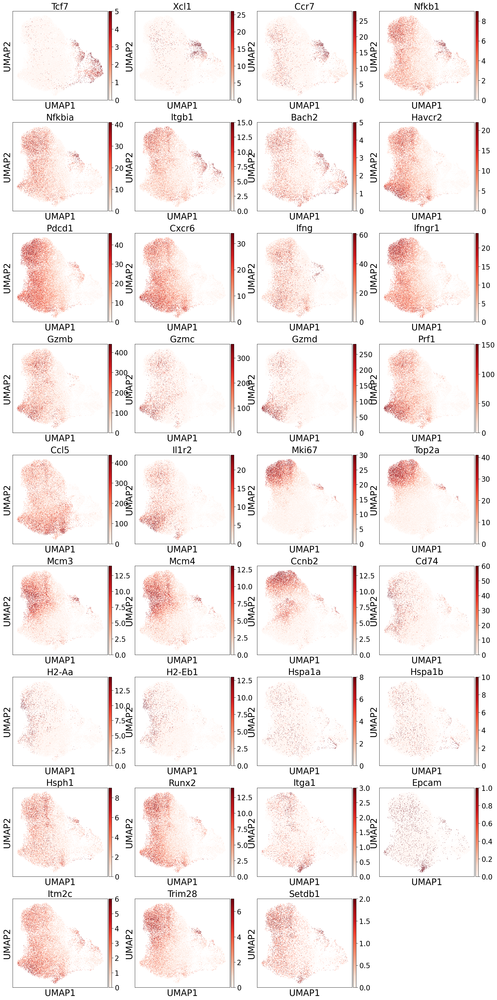

In [35]:
plt.rcParams['figure.figsize'] = (5,5)
sc.pl.umap(adata, color=['Tcf7',  'Xcl1', 'Ccr7', 'Nfkb1', 'Nfkbia', 'Itgb1', 'Bach2',
                        'Havcr2', 'Pdcd1', 'Cxcr6', 'Ifng', 'Ifngr1',
                      'Gzmb', 'Gzmc', 'Gzmd', 'Prf1',
                      'Ccl5',
                      'Il1r2',
                      'Mki67','Top2a', 'Mcm3', 'Mcm4', 'Ccnb2',
                      'Cd74', 'H2-Aa', 'H2-Eb1',
                      'Hspa1a', 'Hspa1b', 'Hsph1',
                      'Runx2',
                      'Itga1', 'Epcam', 'Itm2c',
                     'Trim28', 'Setdb1'], color_map='Reds', vmin='p2', vmax='p98')

In [36]:
def get_cell_type(r):
    leiden05 = r['leiden_0.5']
    leiden075 = r['leiden_0.75']
    leiden1 = r['leiden_1']
    leiden2 = r['leiden_2']
    cell_type = None
    if leiden05 == '6' or leiden05 == '8' or leiden075 == '7':
        cell_type = 'Progenitor'
    if leiden1 == '13':
        cell_type = 'TRM-like'
    if leiden05 == '4':
        cell_type = 'Ccl5+'
    if leiden05 == '0':
        cell_type = 'Granzyme High'
    if leiden1 in ['1', '7', '0']:
        cell_type = 'Ccl5+'
    if r['leiden_3'] == '36':
        cell_type = 'Progenitor Cycling'
    if cell_type:
        return cell_type
    else:
        cell_type = 'Cycling'
        return cell_type

adata.obs['cell_type'] = adata.obs.apply(get_cell_type, axis=1)

In [37]:
# Create a mask for cells to retain and rename
mask_progenitor_ln = ((adata.obs['cell_type'] == 'Progenitor') \
                      | (adata.obs['cell_type'] == 'Progenitor Cycling')) \
                      & (adata.obs['location'] == 'Lymph Nodes')

# Update cell_type labels
adata.obs.loc[mask_progenitor_ln, 'cell_type'] = 'Lymph Node Progenitor'

# Verify the changes
print(adata.obs.groupby(['cell_type', 'location']).size())

cell_type              location   
Ccl5+                  Lymph Nodes        6
                       Tumor          10710
Cycling                Lymph Nodes        4
                       Tumor          15267
Granzyme High          Lymph Nodes        1
                       Tumor           3391
Lymph Node Progenitor  Lymph Nodes     1055
                       Tumor              0
Progenitor             Lymph Nodes        0
                       Tumor           1748
Progenitor Cycling     Lymph Nodes        0
                       Tumor            356
TRM-like               Lymph Nodes        0
                       Tumor            725
dtype: int64


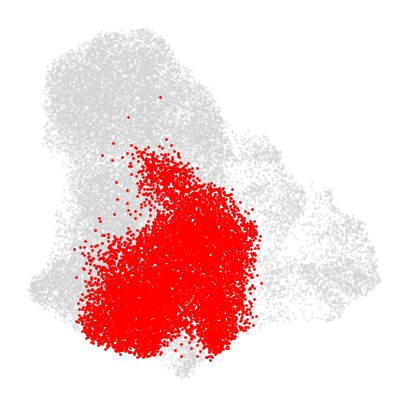

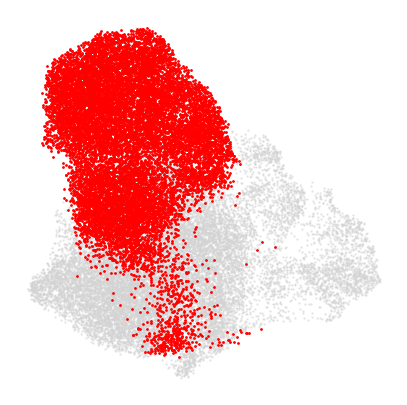

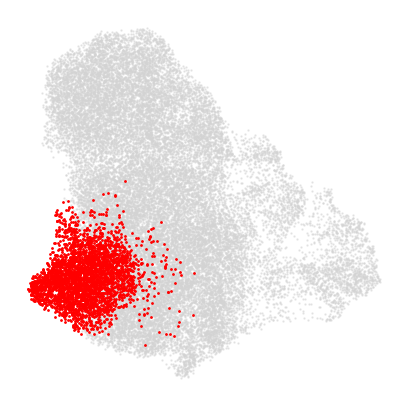

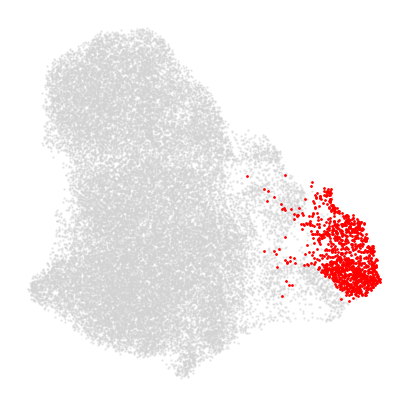

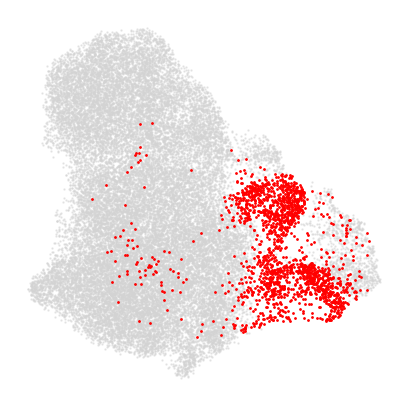

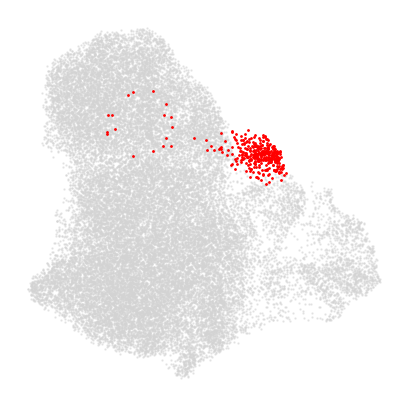

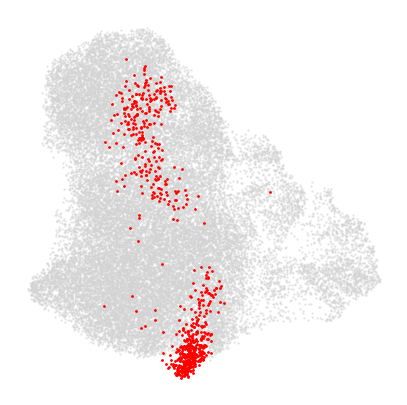

In [38]:
reload(misc)
for cell_type in np.unique(adata.obs['cell_type']):
    misc.draw_overlap_umap(adata, 'cell_type', cell_type, 'red', size=0.5)

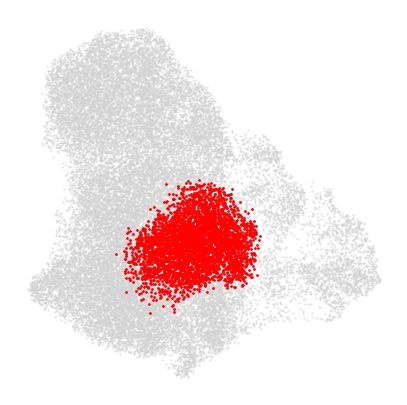

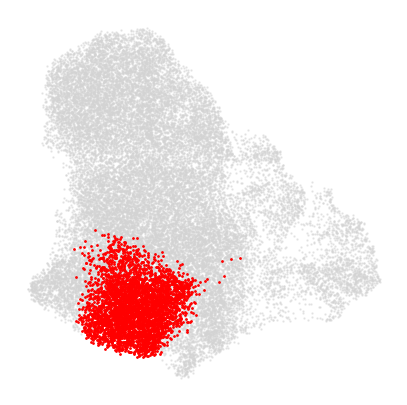

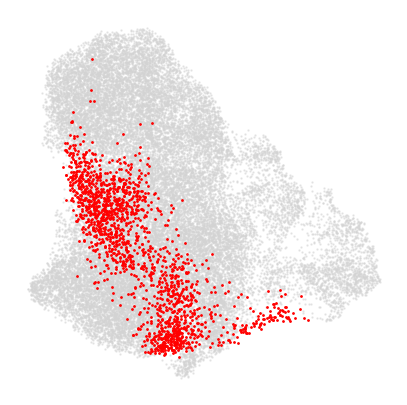

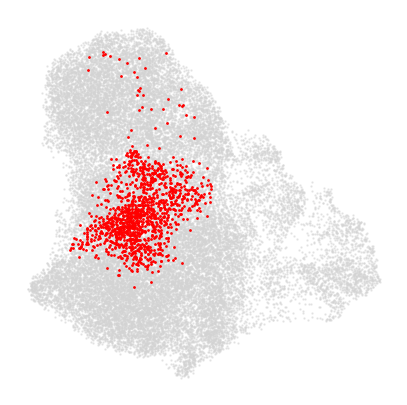

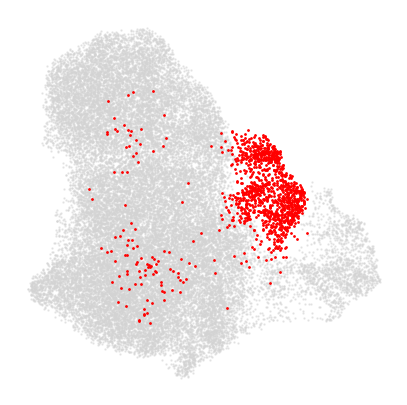

...

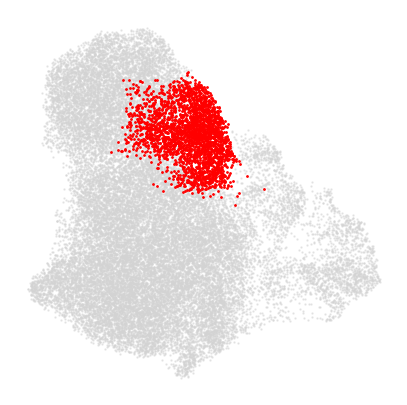

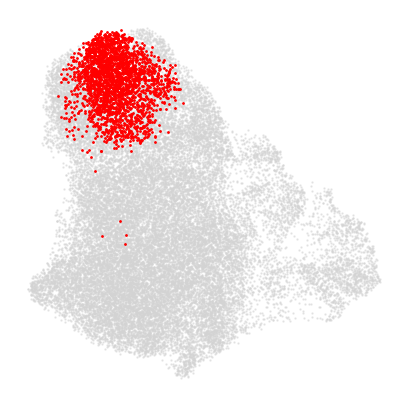

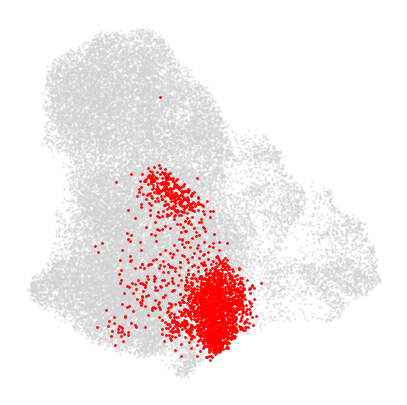

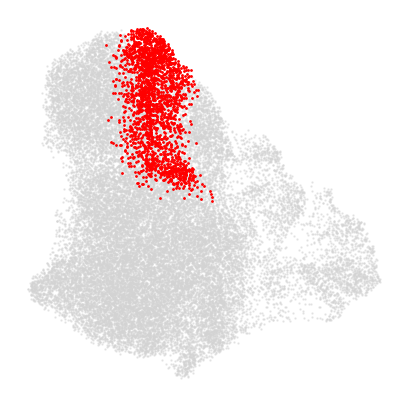

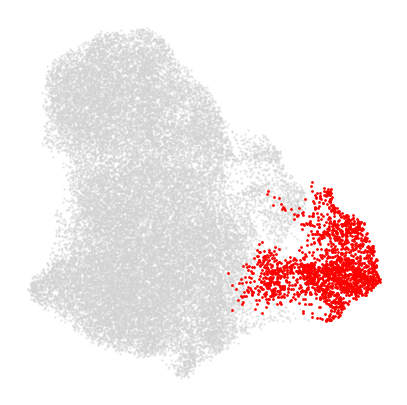

In [39]:
reload(misc)
for cell_type in np.unique(adata.obs['leiden_1']):
    misc.draw_overlap_umap(adata, 'leiden_1', cell_type, 'red', size=0.5)

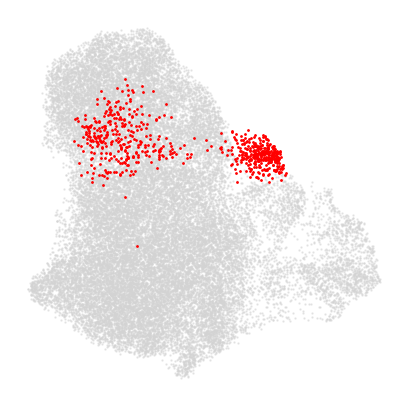

In [40]:
reload(misc)
for cell_type in ['21']:
    misc.draw_overlap_umap(adata, 'leiden_2', cell_type, 'red', size=0.5)

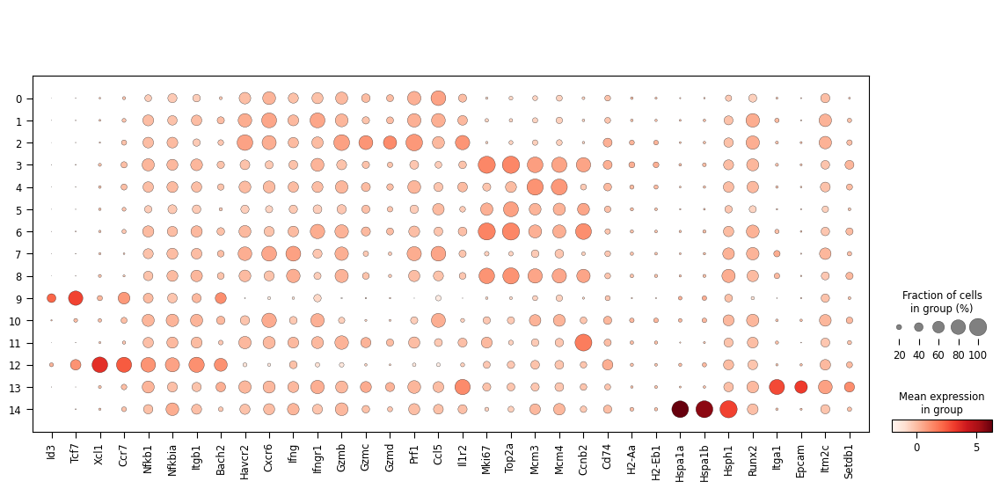

In [41]:
sc.pl.dotplot(adata, ['Id3', 'Tcf7',  'Xcl1', 'Ccr7', 'Nfkb1', 'Nfkbia', 'Itgb1', 'Bach2',
                        'Havcr2', 'Cxcr6', 'Ifng', 'Ifngr1',
                      'Gzmb', 'Gzmc', 'Gzmd', 'Prf1',
                      'Ccl5',
                      'Il1r2',
                      'Mki67','Top2a', 'Mcm3', 'Mcm4', 'Ccnb2',
                      'Cd74', 'H2-Aa', 'H2-Eb1',
                      'Hspa1a', 'Hspa1b', 'Hsph1',
                      'Runx2',
                      'Itga1', 'Epcam', 'Itm2c',
                     'Setdb1'],
              layer='norm_log_zscore',
              groupby='leiden_1',
              dendrogram=False)

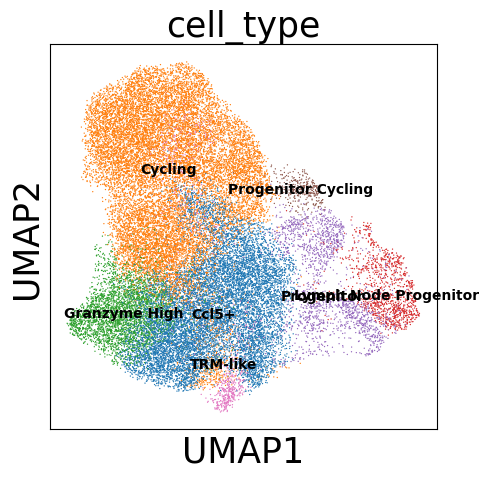

In [42]:
sc.pl.umap(adata, color=['cell_type'],
           legend_loc='on data', cmap='Reds', vmin="p2", vmax="p98")

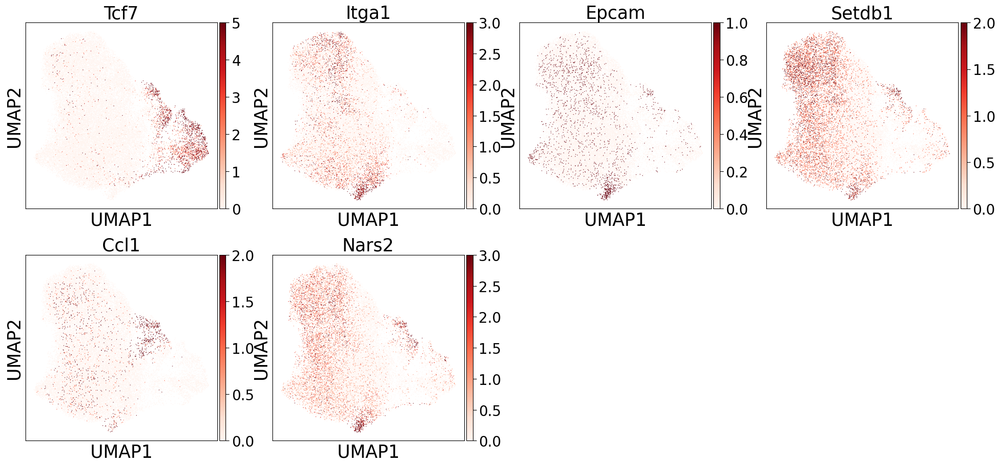

In [43]:
plt.rcParams['figure.figsize'] = (5,5)
sc.pl.umap(adata, color=['Tcf7',
                      'Itga1', 'Epcam', 'Setdb1', 'Ccl1', 'Nars2'], color_map='Reds', vmin='p2', vmax='p98')

In [44]:
adata.obs = adata.obs.drop(columns = ['leiden', 'leiden_0.5', 'leiden_0.75', 'leiden_1', 'leiden_2'])

In [45]:
# adata.write_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/before_final.h5ad")

# Renmaing Columns Again

In [99]:
adata = sc.read_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/before_final.h5ad")

In [100]:
adata.obs['mouse'] = adata.obs.apply(lambda e: f"{e['condition']}_{e['mouse']}", axis=1)

In [101]:
import pandas as pd
import scanpy as sc

# Assuming your adata object is already loaded and available

# Extract the unique mouse identifiers
unique_mice = adata.obs['mouse'].unique()

# Create dictionaries to map old identifiers to new names
pd1_counter = 9  # Starting number for PD-1
iso_counter = 8  # Starting number for Isotype
mouse_mapping = {}

for mouse in unique_mice:
    if 'PD-1' in mouse:
        new_name = f"aPD1:{pd1_counter}"
        mouse_mapping[mouse] = new_name
        pd1_counter += 1
    elif 'Isotype' in mouse:
        new_name = f"Isotype:{iso_counter}"
        mouse_mapping[mouse] = new_name
        iso_counter += 1

# Map the old mouse identifiers to the new names
adata.obs['mouse'] = adata.obs['mouse'].map(mouse_mapping)

# Verify the changes
print(adata.obs['mouse'].value_counts())

aPD1:15       7038
aPD1:20       5524
aPD1:11       3982
Isotype:9     3241
aPD1:10       2362
Isotype:14    2246
Isotype:8     1951
aPD1:19       1683
aPD1:14        991
aPD1:12        921
Isotype:13     792
aPD1:16        592
aPD1:9         331
aPD1:13        320
Isotype:17     241
Isotype:11     224
Isotype:15     172
Isotype:10     167
Isotype:12     147
aPD1:17        116
Isotype:16      84
aPD1:21         55
aPD1:18         44
Isotype:18      39
Name: mouse, dtype: int64


In [102]:
def assign_clone(row):
    if row['all_constructs_str'] == '':
        return ''
    else:
        return f"{row['mouse']}|{row['all_constructs_str']}"

# Apply the function across the rows
adata.obs['clone'] = adata.obs.apply(assign_clone, axis=1)

# Step 2: Update 'clone_size'
clone_size = adata.obs.groupby('clone').size()
adata.obs['clone_size'] = adata.obs['clone'].map(clone_size)

In [109]:
adata.obs['condition'] = adata.obs['condition'].apply(lambda e: e if e=='Isotype' else 'PD1')

In [104]:
adata.obs['cell_type'] = adata.obs['cell_type'].apply(lambda e: 'Progenitor dLN'  if e=='Lymph Node Progenitor' else e)

In [111]:
adata.write_h5ad("/Genomics/pritykinlab/dillon/perturbseq/data/trim28_setdb1/preprocessing/final.h5ad")